# CSE422 — Machine Learning Project

## BRAC University

### Software Quality Prediction: High, Medium, or Low?

---

## Phase 1: Introduction

### What Does This Project Aim to Do?

This project builds machine learning models that predict the **quality label** of a piece of software code — **High**, **Medium**, or **Low** — based on static code metrics such as lines of code, cyclomatic complexity, number of bugs, comment density, presence of unit tests, and the experience level of the code owner.

### What Problem Is It Solving?

Assessing code quality manually is time-consuming and subjective, especially in large codebases with many contributors. Being able to automatically flag low-quality or high-risk code from measurable metrics helps engineering teams prioritize code review effort, catch potential defects earlier, and maintain overall codebase health.

### Motivation

Software metrics like complexity and churn are known proxies for maintainability and bug-proneness in software engineering research. By training classifiers on these metrics, we investigate how well quality can be predicted purely from static, easily-collected code statistics — and where the limits of that prediction lie.

In [ ]:
# ── Imports ──────────────────────────────────────────────────────────────────
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

# Sklearn
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.naive_bayes import GaussianNB
from sklearn.linear_model import LogisticRegression
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, ConfusionMatrixDisplay,
    roc_auc_score, roc_curve, classification_report
)

# TensorFlow / Keras
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout, BatchNormalization
from tensorflow.keras.callbacks import EarlyStopping
from tensorflow.keras.utils import to_categorical

print("All libraries imported successfully!")
print(f"TensorFlow version : {tf.__version__}")
print(f"NumPy version      : {np.__version__}")
print(f"Pandas version     : {pd.__version__}")

# Global plot style
sns.set_theme(style='whitegrid', palette='muted')
plt.rcParams['figure.dpi'] = 120

All libraries imported successfully!
TensorFlow version : 2.20.0
NumPy version      : 2.1.3
Pandas version     : 2.2.3


---

## Phase 2: Dataset Description

### Uploading the Dataset

Run the cell below and select `software_quality_dataset.csv` when prompted (or mount your Drive and update the path instead).

In [ ]:
from google.colab import files
uploaded = files.upload()  # select software_quality_dataset.csv

Saving software_quality_dataset.csv to software_quality_dataset.csv


In [ ]:
# ── Load Dataset ─────────────────────────────────────────────────────────────
df_raw = pd.read_csv('software_quality_dataset.csv')
print(f"Raw dataset shape  : {df_raw.shape}")
print(f"Total features     : {df_raw.shape[1] - 1}")
print(f"Total instances    : {df_raw.shape[0]}")
df_raw.head()

Raw dataset shape  : (1600, 9)
Total features     : 8
Total instances    : 1600


,Lines_of_Code,Cyclomatic_Complexity,Num_Functions,Code_Churn,Comment_Density,Num_Bugs,Has_Unit_Tests,Code_Owner_Experience,Quality_Label
0,356.0,31,144,69.567047,0.467561,2,Yes,4,Medium
1,227.0,15,104,131.844422,0.795643,2,No,5,High
2,9674.0,47,141,118.729027,0.316839,5,No,1,High
3,6967.0,42,107,194.397155,0.971883,5,Yes,3,Low
4,7954.0,35,114,69.202293,0.559417,1,No,8,Medium


### 2.1 Feature Count & Problem Type

The dataset contains **9 columns** — 8 input features and 1 target column (`Quality_Label`).

**This is a Classification Problem** because the target variable `Quality_Label` takes discrete categorical values: `High`, `Medium`, and `Low`. Since we are predicting a category label and not a continuous quantity, this is multi-class classification.

### 2.2 Feature Types

| Type | Features |
|------|----------|
| **Numerical (continuous/discrete)** | Lines_of_Code, Cyclomatic_Complexity, Num_Functions, Code_Churn, Comment_Density, Num_Bugs, Code_Owner_Experience |
| **Categorical (binary)** | Has_Unit_Tests (Yes/No) |
| **Target (categorical, 3 classes)** | Quality_Label (High / Medium / Low) |

In [ ]:
# ── Feature Overview ─────────────────────────────────────────────────────────
print("Columns & Data Types:")
print(df_raw.dtypes.to_string())
print()
print("Basic Statistics:")
df_raw.describe()

Columns & Data Types:
Lines_of_Code            float64
Cyclomatic_Complexity      int64
Num_Functions              int64
Code_Churn               float64
Comment_Density          float64
Num_Bugs                   int64
Has_Unit_Tests            object
Code_Owner_Experience      int64
Quality_Label             object

Basic Statistics:


,Lines_of_Code,Cyclomatic_Complexity,Num_Functions,Code_Churn,Comment_Density,Num_Bugs,Code_Owner_Experience
count,1520.000000,1600.000000,1600.000000,1520.000000,1520.000000,1600.000000,1600.000000
mean,4939.269737,25.076875,103.178125,102.572291,0.549370,2.934375,5.045000
std,2867.248259,13.879621,55.503710,50.546329,0.256137,1.715928,2.559701
min,106.000000,1.000000,5.000000,-64.283310,0.101037,0.000000,1.000000
25%,2490.750000,13.000000,56.000000,67.509852,0.337596,2.000000,3.000000
50%,4860.000000,25.000000,104.000000,104.007452,0.542108,3.000000,5.000000
75%,7455.250000,37.000000,152.000000,138.619113,0.765766,4.000000,7.000000
max,9998.000000,49.000000,199.000000,295.139936,0.999976,10.000000,9.000000


### 2.3 Target Variable — Class Distribution (Imbalance Check)

Target Class Distribution:
Quality_Label
High      566
Low       533
Medium    501
Name: count, dtype: int64

Is the dataset balanced? Yes


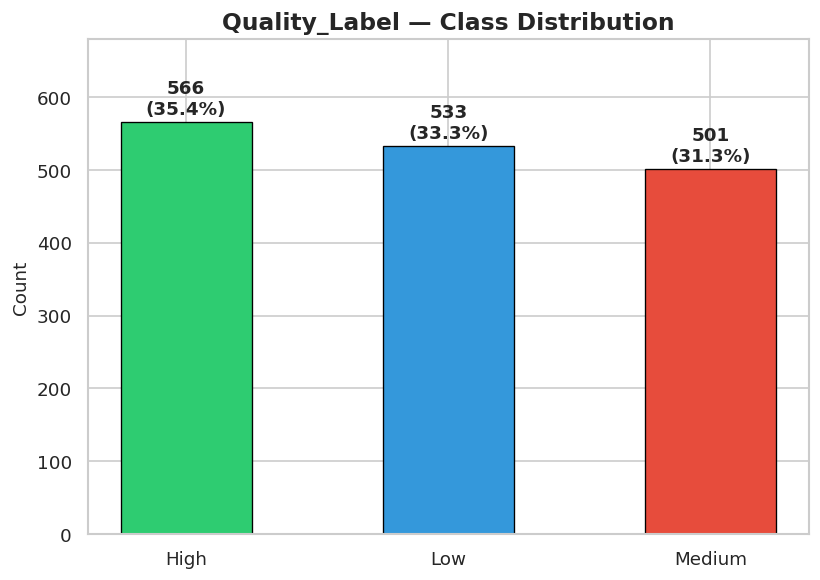

In [ ]:
# ── Class distribution ────────────────────────────────────────────────────────
target_counts = df_raw['Quality_Label'].value_counts()
print("Target Class Distribution:")
print(target_counts)
print(f"\nIs the dataset balanced? {'Yes' if target_counts.std() < target_counts.mean()*0.15 else 'No — the dataset is somewhat IMBALANCED'}")

# Bar chart
colors = ['#2ecc71', '#3498db', '#e74c3c']
fig, ax = plt.subplots(figsize=(7, 5))
bars = ax.bar(target_counts.index, target_counts.values, color=colors,
              edgecolor='black', linewidth=0.8, width=0.5)
for bar, val in zip(bars, target_counts.values):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 5,
            f'{val}\n({val/len(df_raw)*100:.1f}%)',
            ha='center', va='bottom', fontsize=11, fontweight='bold')
ax.set_title('Quality_Label — Class Distribution', fontsize=14, fontweight='bold')
ax.set_ylabel('Count', fontsize=11)
ax.set_ylim(0, target_counts.max()*1.2)
plt.tight_layout()
plt.show()

**Observation:** The three classes are close in size (roughly 31–35% each), so this dataset is **mildly imbalanced at most** — no aggressive resampling is required, though we still use stratified splitting to be safe.

### 2.4 Correlation Heatmap

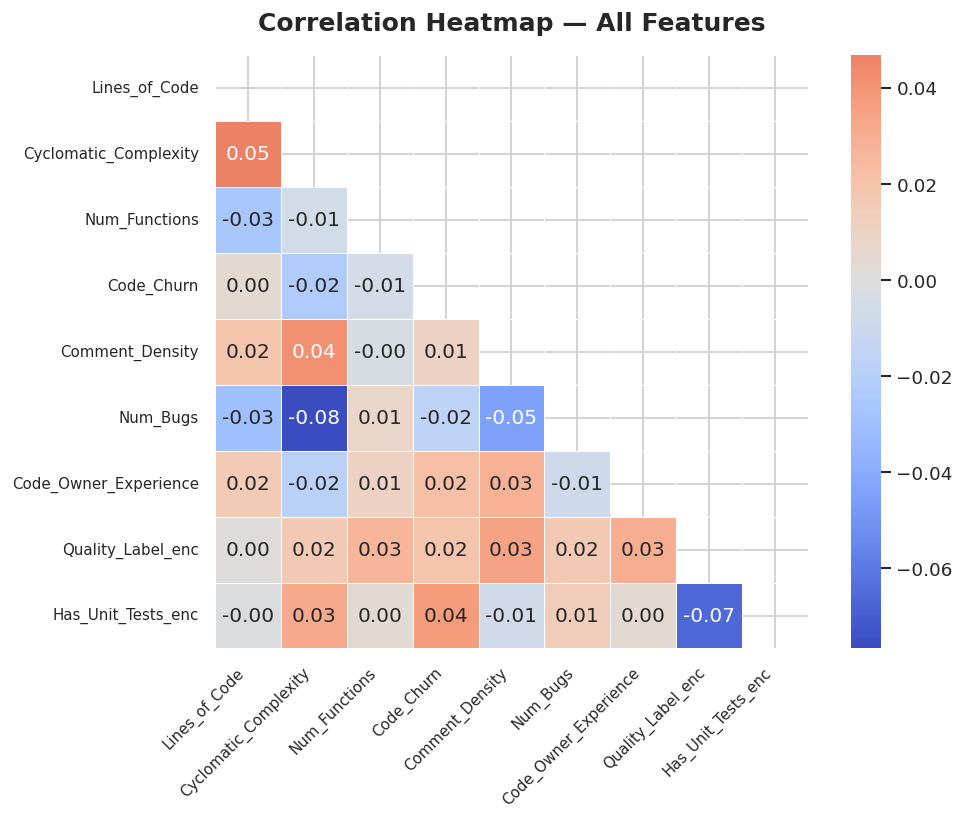

In [ ]:
# ── Encode target temporarily for correlation ─────────────────────────────────
df_corr = df_raw.copy()
le_temp = LabelEncoder()
df_corr['Quality_Label_enc'] = le_temp.fit_transform(df_corr['Quality_Label'].astype(str))
df_corr['Has_Unit_Tests_enc'] = df_corr['Has_Unit_Tests'].map({'No': 0, 'Yes': 1})
df_corr_num = df_corr.drop(columns=['Quality_Label', 'Has_Unit_Tests'])

corr_matrix = df_corr_num.corr()

plt.figure(figsize=(9, 7))
mask = np.triu(np.ones_like(corr_matrix, dtype=bool))
sns.heatmap(
    corr_matrix,
    annot=True,
    fmt='.2f',
    cmap='coolwarm',
    center=0,
    linewidths=0.3,
    mask=mask,
    square=True
)
plt.title('Correlation Heatmap — All Features', fontsize=15, fontweight='bold', pad=15)
plt.xticks(rotation=45, ha='right', fontsize=9)
plt.yticks(fontsize=9)
plt.tight_layout()
plt.show()

Feature correlations with Quality_Label (by absolute value):
Has_Unit_Tests_enc       0.066401
Comment_Density          0.033929
Code_Owner_Experience    0.030223
Num_Functions            0.026068
Code_Churn               0.019487
Num_Bugs                 0.015963
Cyclomatic_Complexity    0.015905
Lines_of_Code            0.000813


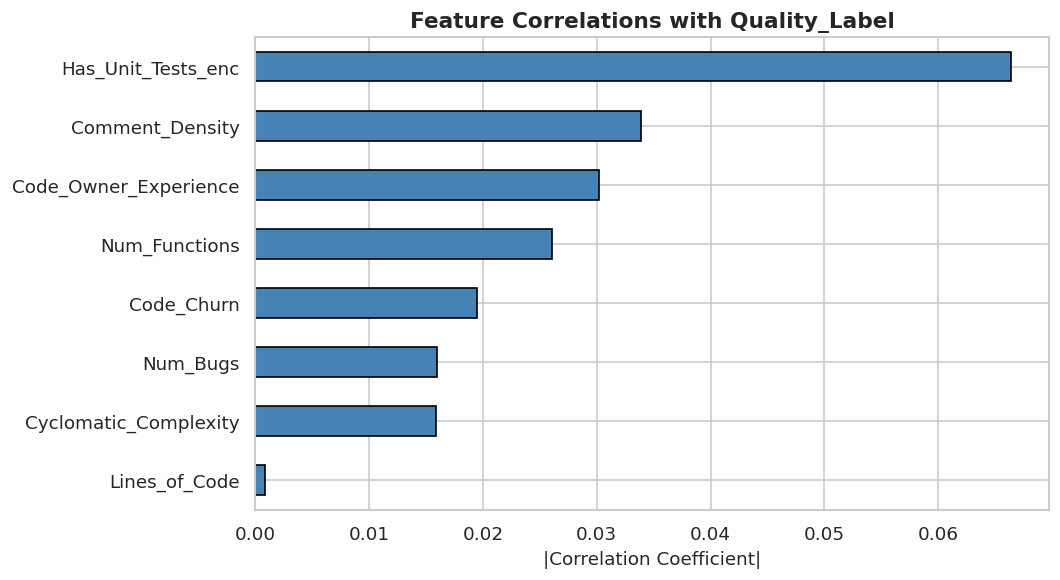

In [ ]:
# ── Top correlations with target ──────────────────────────────────────────────
top_corr = corr_matrix['Quality_Label_enc'].drop('Quality_Label_enc').abs().sort_values(ascending=False)
print("Feature correlations with Quality_Label (by absolute value):")
print(top_corr.to_string())

fig, ax = plt.subplots(figsize=(9, 5))
top_corr.sort_values().plot(kind='barh', ax=ax, color='steelblue', edgecolor='black')
ax.set_title('Feature Correlations with Quality_Label', fontsize=13, fontweight='bold')
ax.set_xlabel('|Correlation Coefficient|', fontsize=11)
plt.tight_layout()
plt.show()

### 2.5 Correlation Analysis Findings

*(Update these bullet points with what you actually observe once you run the cells above — as a starting point, here's what to look for:)*

- Check whether **Num_Bugs** and **Cyclomatic_Complexity** show the strongest (likely negative) correlation with quality — more bugs/complexity would be expected to push code toward `Low` quality.
- Check whether **Has_Unit_Tests** and **Comment_Density** correlate positively with quality — better-tested, better-documented code tends to be higher quality.
- Note how *weak or strong* all the correlations are overall. If every correlation is under ~0.1, that's an important finding: it tells us the features may carry little linear signal about quality, which will show up later as low model accuracy (close to the ~33% random-guess baseline for 3 balanced classes).

### 2.6 Exploratory Data Analysis (EDA)

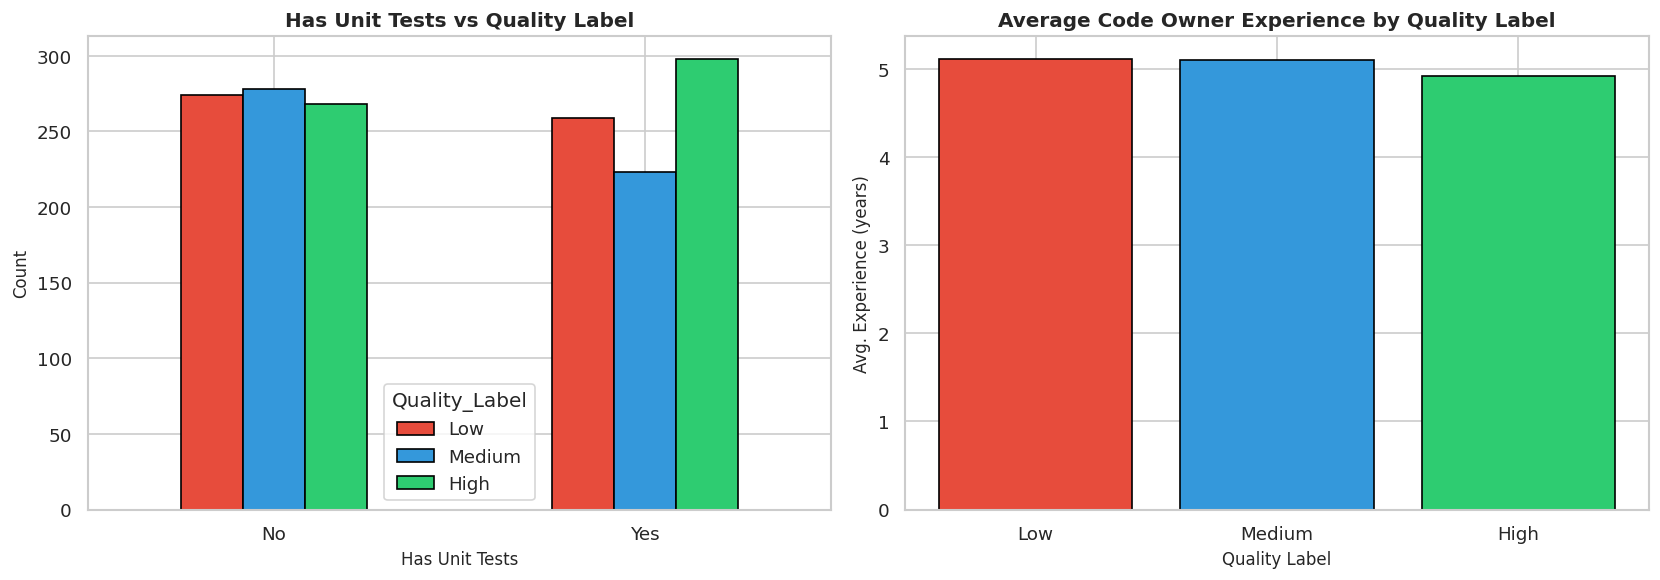

In [ ]:
# ── EDA: Has_Unit_Tests vs Quality_Label ────────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

tests_target = df_corr.groupby(['Has_Unit_Tests', 'Quality_Label']).size().unstack(fill_value=0)
tests_target = tests_target[['Low', 'Medium', 'High']]
tests_target.plot(kind='bar', ax=axes[0],
                  color=['#e74c3c','#3498db','#2ecc71'], edgecolor='black')
axes[0].set_title('Has Unit Tests vs Quality Label', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Has Unit Tests', fontsize=10)
axes[0].set_ylabel('Count', fontsize=10)
axes[0].set_xticklabels(tests_target.index, rotation=0)

exp_target = df_corr.groupby(['Quality_Label'])['Code_Owner_Experience'].mean().reindex(['Low','Medium','High'])
axes[1].bar(exp_target.index, exp_target.values,
            color=['#e74c3c','#3498db','#2ecc71'], edgecolor='black')
axes[1].set_title('Average Code Owner Experience by Quality Label', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Quality Label', fontsize=10)
axes[1].set_ylabel('Avg. Experience (years)', fontsize=10)

plt.tight_layout()
plt.show()

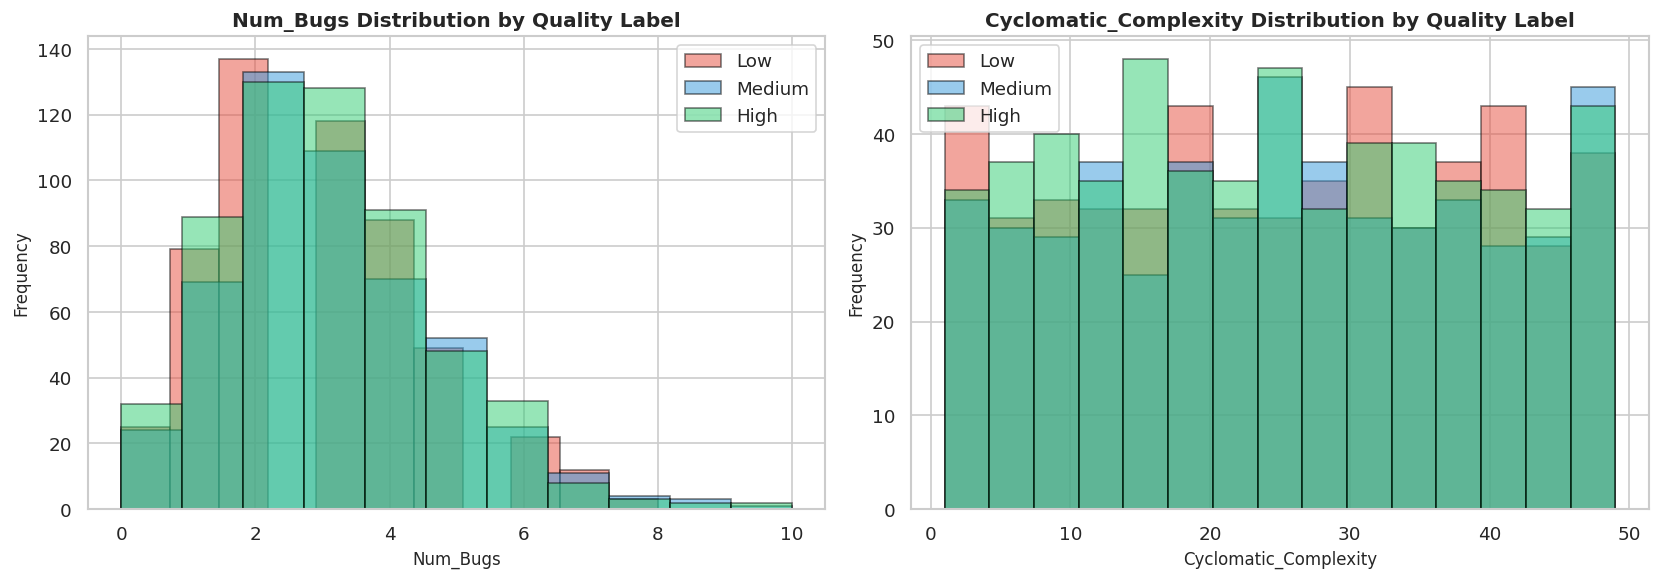

In [ ]:
# ── EDA: Num_Bugs distribution by Quality_Label ─────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for target_class, color in zip(['Low', 'Medium', 'High'], ['#e74c3c', '#3498db', '#2ecc71']):
    subset = df_corr[df_corr['Quality_Label'] == target_class]['Num_Bugs'].dropna()
    axes[0].hist(subset, bins=11, alpha=0.5, label=target_class, color=color, edgecolor='black')
axes[0].set_title('Num_Bugs Distribution by Quality Label', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Num_Bugs', fontsize=10)
axes[0].set_ylabel('Frequency', fontsize=10)
axes[0].legend()

for target_class, color in zip(['Low', 'Medium', 'High'], ['#e74c3c', '#3498db', '#2ecc71']):
    subset = df_corr[df_corr['Quality_Label'] == target_class]['Cyclomatic_Complexity'].dropna()
    axes[1].hist(subset, bins=15, alpha=0.5, label=target_class, color=color, edgecolor='black')
axes[1].set_title('Cyclomatic_Complexity Distribution by Quality Label', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Cyclomatic_Complexity', fontsize=10)
axes[1].set_ylabel('Frequency', fontsize=10)
axes[1].legend()

plt.tight_layout()
plt.show()

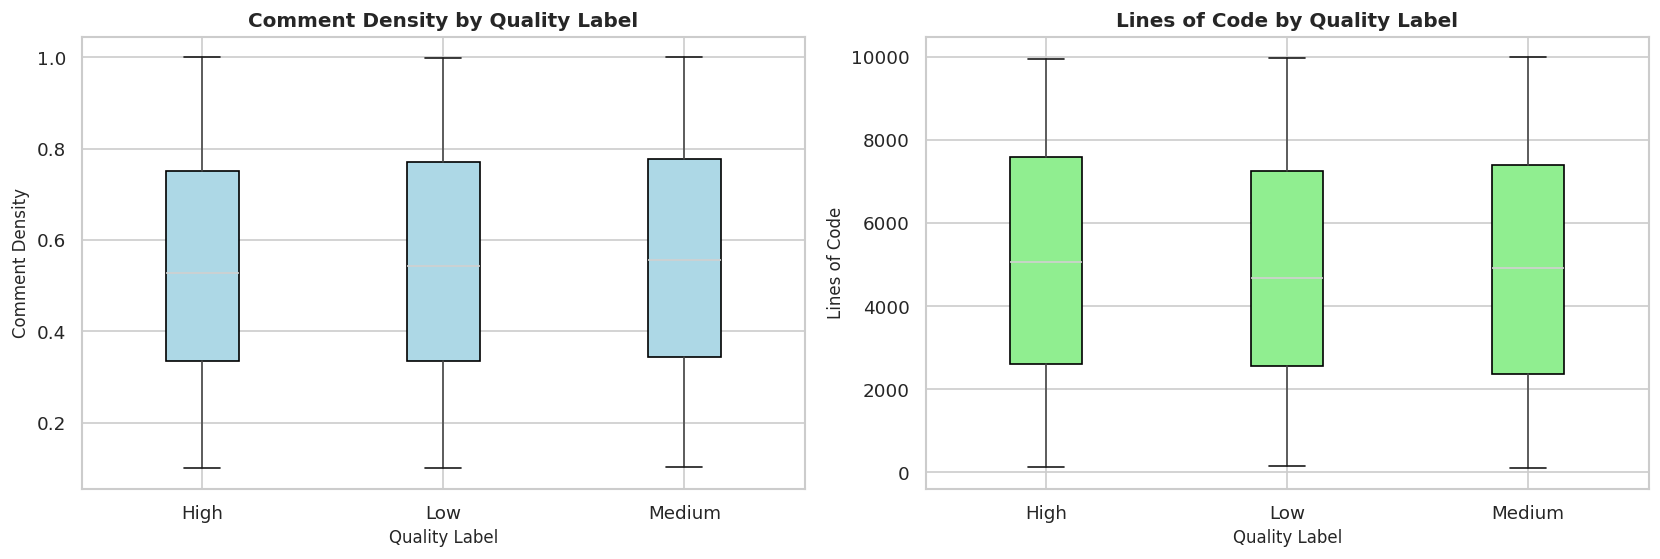

In [ ]:
# ── EDA: Comment_Density & Lines_of_Code boxplots ───────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

df_corr.boxplot(column='Comment_Density', by='Quality_Label', ax=axes[0],
                patch_artist=True, boxprops=dict(facecolor='lightblue'))
axes[0].set_title('Comment Density by Quality Label', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Quality Label', fontsize=10)
axes[0].set_ylabel('Comment Density', fontsize=10)
plt.sca(axes[0]); plt.title('Comment Density by Quality Label', fontsize=12, fontweight='bold')

df_corr.boxplot(column='Lines_of_Code', by='Quality_Label', ax=axes[1],
                patch_artist=True, boxprops=dict(facecolor='lightgreen'))
axes[1].set_title('Lines of Code by Quality Label', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Quality Label', fontsize=10)
axes[1].set_ylabel('Lines of Code', fontsize=10)
plt.sca(axes[1]); plt.title('Lines of Code by Quality Label', fontsize=12, fontweight='bold')

plt.suptitle('')
plt.tight_layout()
plt.show()

**EDA Key Takeaways:** *(fill in based on what you actually observe from the plots above — a few things to check:)*

- Do codebases **without unit tests** skew toward `Low` quality more than tested ones?
- Does **average code owner experience** rise from `Low` → `Medium` → `High` quality, or is it flat across classes?
- Do `Num_Bugs` and `Cyclomatic_Complexity` distributions shift visibly across quality classes, or do they overlap heavily (which would suggest weak predictive power)?
- Are `Comment_Density` and `Lines_of_Code` meaningfully different across classes, or roughly similar?

---

## Phase 3: Dataset Pre-Processing

In [ ]:
# Working copy
df = df_raw.copy()

### Problem 1 — Missing Values in Feature Columns

**Fault:** Three numerical feature columns — `Lines_of_Code`, `Code_Churn`, and `Comment_Density` — each contain **80 missing values** (5% of rows).

**Solution:** Use **median imputation** for these columns. Median is preferred over mean because it's robust to outliers and skewed distributions, and we don't want to lose 5% of our rows by dropping them.

In [ ]:
print("Missing values per feature BEFORE imputation:")
missing = df.isnull().sum()
print(missing[missing > 0].to_string())

from sklearn.impute import SimpleImputer
cols_to_impute = ['Lines_of_Code', 'Code_Churn', 'Comment_Density']
imputer = SimpleImputer(strategy='median')
df[cols_to_impute] = imputer.fit_transform(df[cols_to_impute])
print("\nMissing values AFTER imputation:", df.isnull().sum().sum())

Missing values per feature BEFORE imputation:
Lines_of_Code      80
Code_Churn         80
Comment_Density    80

Missing values AFTER imputation: 0


### Problem 2 — Categorical Feature Encoding (`Has_Unit_Tests`)

**Fault:** `Has_Unit_Tests` is stored as text (`Yes`/`No`). Machine learning models require numeric input.

**Solution:** Apply **binary encoding** since this is a two-level category: `No` → 0, `Yes` → 1.

In [ ]:
df['Has_Unit_Tests'] = df['Has_Unit_Tests'].map({'No': 0, 'Yes': 1})
print("Has_Unit_Tests encoded. Value counts:")
print(df['Has_Unit_Tests'].value_counts())

Has_Unit_Tests encoded. Value counts:
Has_Unit_Tests
0    820
1    780
Name: count, dtype: int64


### Problem 3 — Target Column Encoding (`Quality_Label`)

**Fault:** The `Quality_Label` column contains string labels (`High`, `Medium`, `Low`). Machine learning models require numeric targets.

**Solution:** Apply **Label Encoding** to convert text labels to integers (0, 1, 2).

In [ ]:
le = LabelEncoder()
df['Quality_Label_enc'] = le.fit_transform(df['Quality_Label'])
print("Label mapping:")
for cls, code_val in zip(le.classes_, le.transform(le.classes_)):
    print(f"  {cls} -> {code_val}")

Label mapping:
  High -> 0
  Low -> 1
  Medium -> 2


Final dataset shape : (1600, 10)
Total NaN values    : 0
Class distribution  :
Quality_Label
High      566
Low       533
Medium    501
Name: count, dtype: int64


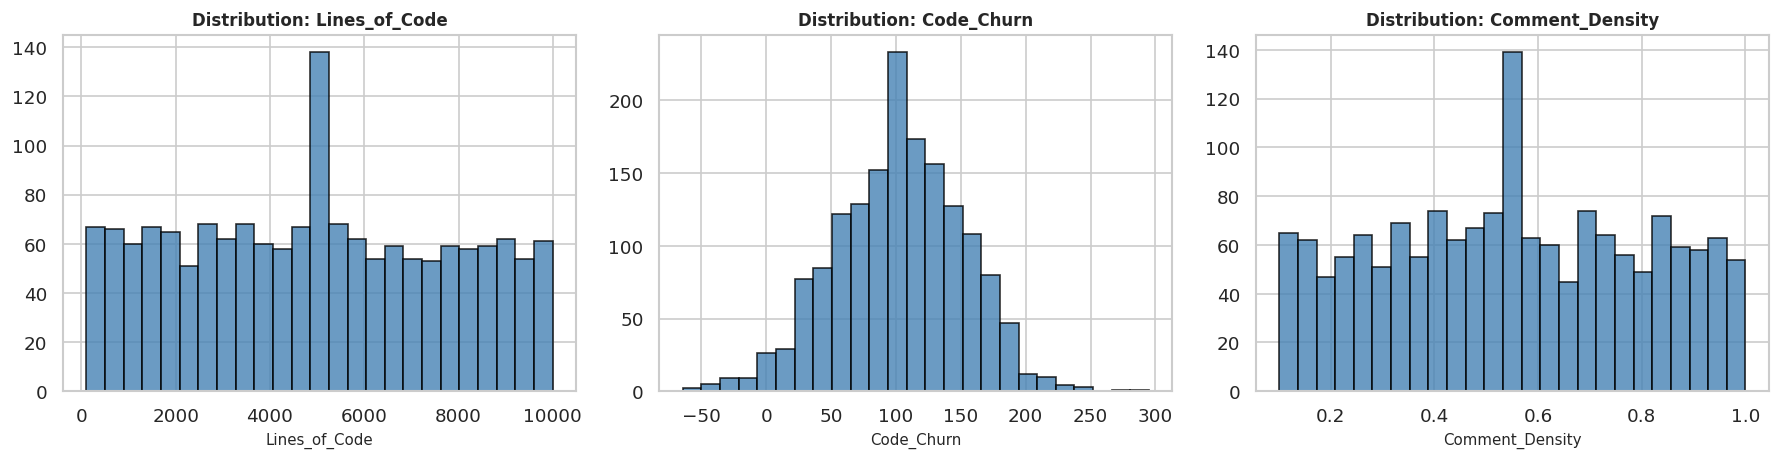

In [ ]:
# ── Post-Processing Summary ───────────────────────────────────────────────────
print(f"Final dataset shape : {df.shape}")
print(f"Total NaN values    : {df.isnull().sum().sum()}")
print(f"Class distribution  :")
print(df['Quality_Label'].value_counts())

# Distribution plots after preprocessing
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, ['Lines_of_Code', 'Code_Churn', 'Comment_Density']):
    ax.hist(df[col], bins=25, color='steelblue', edgecolor='black', alpha=0.8)
    ax.set_title(f'Distribution: {col}', fontsize=10, fontweight='bold')
    ax.set_xlabel(col, fontsize=9)
plt.tight_layout()
plt.show()

---

## Phase 4: Data Splitting

Since the class distribution is close to balanced but not perfectly equal, we use **Stratified Splitting** to ensure each split maintains the original class proportions.

**Split ratio: 80% Train / 20% Test**.

In [ ]:
feature_cols_clean = [c for c in df.columns if c not in ['Quality_Label', 'Quality_Label_enc']]
X = df[feature_cols_clean].values
y = df['Quality_Label_enc'].values

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y        # Stratified split
)

print(f"Training set   : {X_train.shape[0]} samples ({X_train.shape[0]/len(X)*100:.1f}%)")
print(f"Test set       : {X_test.shape[0]} samples ({X_test.shape[0]/len(X)*100:.1f}%)")
print(f"Feature count  : {X_train.shape[1]}")
print("\nClass distribution in Training set:")
unique, counts = np.unique(y_train, return_counts=True)
for u, c in zip(unique, counts):
    print(f"  {le.classes_[u]}: {c} ({c/len(y_train)*100:.1f}%)")

Training set   : 1280 samples (80.0%)
Test set       : 320 samples (20.0%)
Feature count  : 8

Class distribution in Training set:
  High: 453 (35.4%)
  Low: 426 (33.3%)
  Medium: 401 (31.3%)


---

## Phase 5: Scaling / Normalization

**Why scale?** Features like `Lines_of_Code` (range ~100–10000) and `Num_Bugs` (range 0–10) are on very different scales. Distance-based and gradient-descent-based algorithms (Logistic Regression, Neural Network) are sensitive to feature scale.

We apply **StandardScaler** (zero mean, unit variance). Note: The scaler is **fit on training data only** and then applied to both train and test sets to prevent data leakage.

Naive Bayes assumes features are independent Gaussians, so scaling doesn't hurt it either.

Scaling applied: StandardScaler (zero mean, unit variance)
Training set mean (post-scale): 0.0000
Training set std  (post-scale): 1.0000


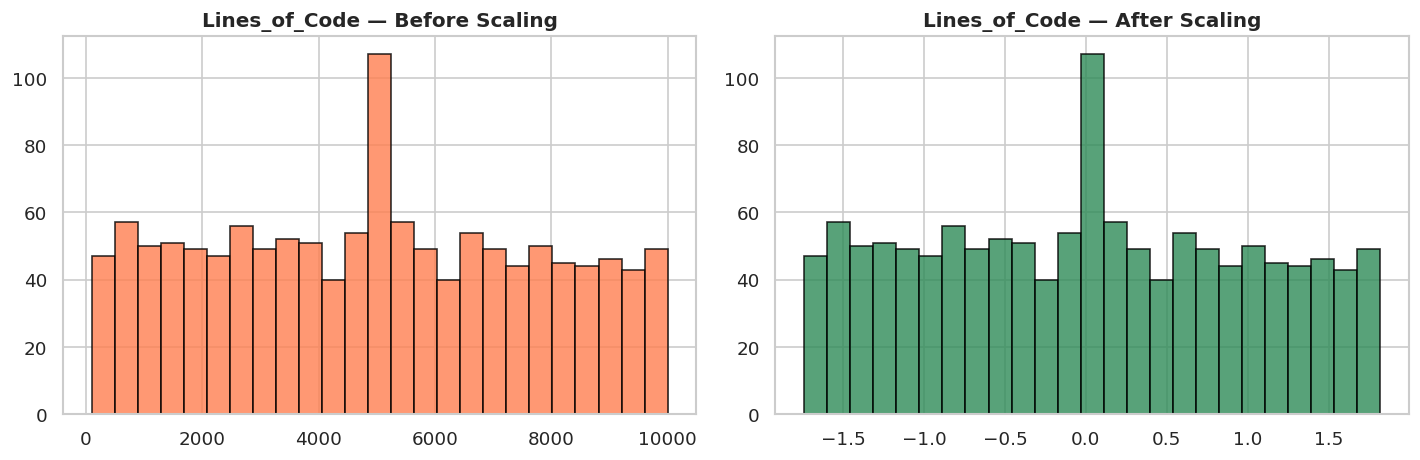

In [ ]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)   # fit + transform on train
X_test_scaled  = scaler.transform(X_test)         # transform only on test

print("Scaling applied: StandardScaler (zero mean, unit variance)")
print(f"Training set mean (post-scale): {X_train_scaled.mean():.4f}")
print(f"Training set std  (post-scale): {X_train_scaled.std():.4f}")

# Visualize before/after for one feature
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
loc_idx = feature_cols_clean.index('Lines_of_Code')
axes[0].hist(X_train[:, loc_idx], bins=25, color='coral', edgecolor='black', alpha=0.8)
axes[0].set_title('Lines_of_Code — Before Scaling', fontweight='bold')
axes[1].hist(X_train_scaled[:, loc_idx], bins=25, color='seagreen', edgecolor='black', alpha=0.8)
axes[1].set_title('Lines_of_Code — After Scaling', fontweight='bold')
plt.tight_layout()
plt.show()

---

## Phase 6: Model Training & Testing

We train **4 models**:

1. **Naive Bayes** (GaussianNB)
2. **Logistic Regression**
3. **Neural Network** (TensorFlow/Keras)
4. **KMeans** (Unsupervised — treated as clustering)

A helper dictionary will store all results for comparison.

In [ ]:
# Results storage
results = {}

### Model 1 — Naive Bayes (GaussianNB)

In [ ]:
nb_model = GaussianNB()
nb_model.fit(X_train_scaled, y_train)
nb_pred  = nb_model.predict(X_test_scaled)
nb_proba = nb_model.predict_proba(X_test_scaled)

nb_acc = accuracy_score(y_test, nb_pred)
print(f"Naive Bayes Accuracy: {nb_acc:.4f} ({nb_acc*100:.2f}%)")
print("\nClassification Report:")
print(classification_report(y_test, nb_pred, target_names=le.classes_))

results['Naive Bayes'] = {
    'pred'  : nb_pred,
    'proba' : nb_proba,
    'acc'   : nb_acc
}

Naive Bayes Accuracy: 0.3469 (34.69%)

Classification Report:
              precision    recall  f1-score   support

        High       0.35      0.50      0.41       113
         Low       0.32      0.33      0.33       107
      Medium       0.37      0.20      0.26       100

    accuracy                           0.35       320
   macro avg       0.35      0.34      0.33       320
weighted avg       0.35      0.35      0.34       320



### Model 2 — Logistic Regression

In [ ]:
lr_model = LogisticRegression(
    max_iter=1000,
    multi_class='multinomial',
    solver='lbfgs',
    random_state=42,
    C=1.0
)
lr_model.fit(X_train_scaled, y_train)
lr_pred  = lr_model.predict(X_test_scaled)
lr_proba = lr_model.predict_proba(X_test_scaled)

lr_acc = accuracy_score(y_test, lr_pred)
print(f"Logistic Regression Accuracy: {lr_acc:.4f} ({lr_acc*100:.2f}%)")
print("\nClassification Report:")
print(classification_report(y_test, lr_pred, target_names=le.classes_))

results['Logistic Regression'] = {
    'pred'  : lr_pred,
    'proba' : lr_proba,
    'acc'   : lr_acc
}

Logistic Regression Accuracy: 0.3250 (32.50%)

Classification Report:
              precision    recall  f1-score   support

        High       0.36      0.55      0.43       113
         Low       0.23      0.15      0.18       107
      Medium       0.34      0.26      0.29       100

    accuracy                           0.33       320
   macro avg       0.31      0.32      0.30       320
weighted avg       0.31      0.32      0.31       320



### Model 3 — Neural Network (TensorFlow / Keras)

In [ ]:
tf.random.set_seed(42)
n_classes = len(le.classes_)

# One-hot encode labels for NN
y_train_ohe = to_categorical(y_train, num_classes=n_classes)
y_test_ohe  = to_categorical(y_test,  num_classes=n_classes)

# Build model
nn_model = Sequential([
    Dense(128, activation='relu', input_shape=(X_train_scaled.shape[1],)),
    BatchNormalization(),
    Dropout(0.3),
    Dense(64, activation='relu'),
    BatchNormalization(),
    Dropout(0.3),
    Dense(32, activation='relu'),
    Dense(n_classes, activation='softmax')
])

nn_model.compile(
    optimizer='adam',
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

nn_model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 128)            │         1,152 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 128)            │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 64)             │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 3)              │            99 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 12,355 (48.26 KB)

 Trainable params: 11,971 (46.76 KB)

 Non-trainable params: 384 (1.50 KB)

In [ ]:
early_stop = EarlyStopping(monitor='val_loss', patience=10, restore_best_weights=True)

history = nn_model.fit(
    X_train_scaled, y_train_ohe,
    epochs=100,
    batch_size=32,
    validation_split=0.15,
    callbacks=[early_stop],
    verbose=1
)

Epoch 1/100
34/34 ━━━━━━━━━━━━━━━━━━━━ 3s 13ms/step - accuracy: 0.3502 - loss: 1.3507 - val_accuracy: 0.3177 - val_loss: 1.1116
Epoch 2/100
34/34 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.3438 - loss: 1.2182 - val_accuracy: 0.3333 - val_loss: 1.1142
Epoch 3/100
34/34 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.3640 - loss: 1.1984 - val_accuracy: 0.3490 - val_loss: 1.1180
Epoch 4/100
34/34 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.3713 - loss: 1.1448 - val_accuracy: 0.3438 - val_loss: 1.1238
Epoch 5/100
34/34 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.4099 - loss: 1.1079 - val_accuracy: 0.3490 - val_loss: 1.1285
Epoch 6/100
34/34 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.3851 - loss: 1.1199 - val_accuracy: 0.3333 - val_loss: 1.1266
Epoch 7/100
34/34 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.3879 - loss: 1.1195 - val_accuracy: 0.3542 - val_loss: 1.1308
Epoch 8/100
34/34 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.4283 - loss: 1.0905 - val_accuracy: 0.3125 - 

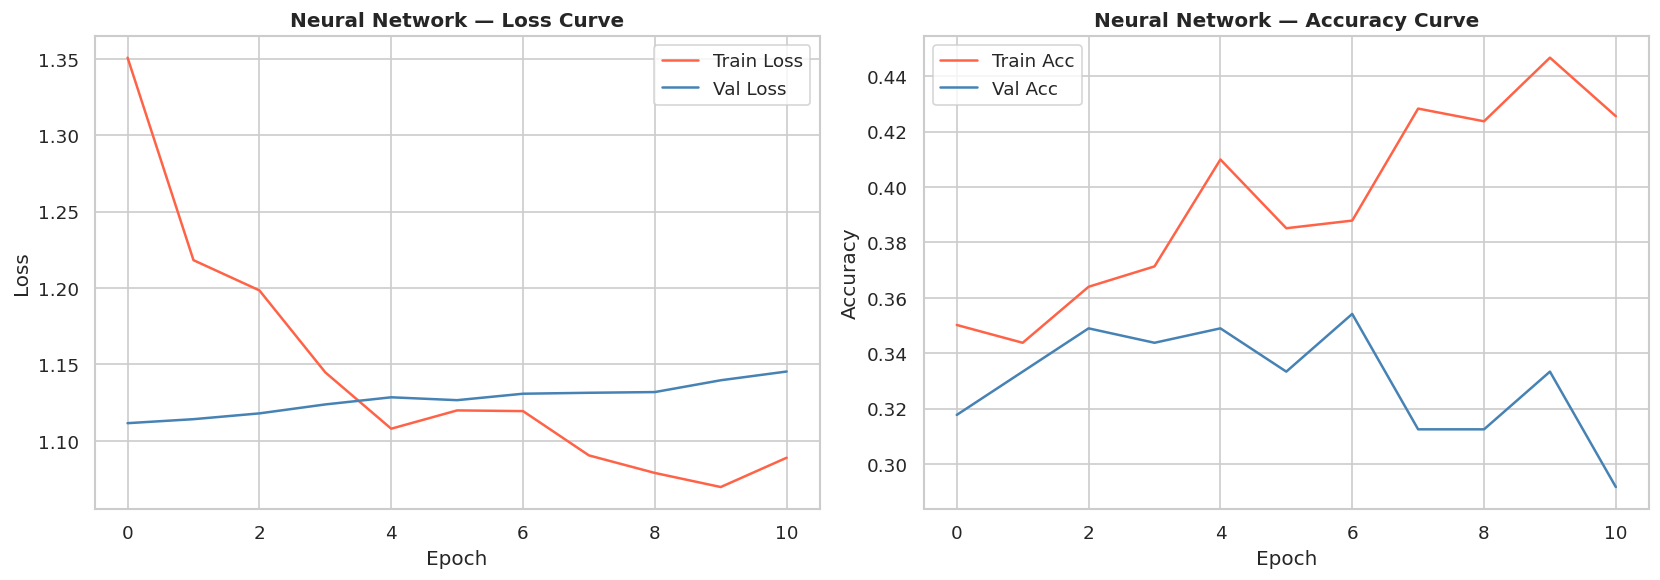

In [ ]:
# Plot training history
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(history.history['loss'],     label='Train Loss', color='tomato')
axes[0].plot(history.history['val_loss'], label='Val Loss',   color='steelblue')
axes[0].set_title('Neural Network — Loss Curve', fontweight='bold')
axes[0].set_xlabel('Epoch'); axes[0].set_ylabel('Loss')
axes[0].legend()

axes[1].plot(history.history['accuracy'],     label='Train Acc', color='tomato')
axes[1].plot(history.history['val_accuracy'], label='Val Acc',   color='steelblue')
axes[1].set_title('Neural Network — Accuracy Curve', fontweight='bold')
axes[1].set_xlabel('Epoch'); axes[1].set_ylabel('Accuracy')
axes[1].legend()

plt.tight_layout()
plt.show()

In [ ]:
nn_proba = nn_model.predict(X_test_scaled)
nn_pred  = np.argmax(nn_proba, axis=1)
nn_acc   = accuracy_score(y_test, nn_pred)

print(f"Neural Network Accuracy: {nn_acc:.4f} ({nn_acc*100:.2f}%)")
print("\nClassification Report:")
print(classification_report(y_test, nn_pred, target_names=le.classes_))

results['Neural Network'] = {
    'pred'  : nn_pred,
    'proba' : nn_proba,
    'acc'   : nn_acc
}

10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step  
Neural Network Accuracy: 0.3156 (31.56%)

Classification Report:
              precision    recall  f1-score   support

        High       0.34      0.20      0.26       113
         Low       0.31      0.32      0.32       107
      Medium       0.30      0.44      0.36       100

    accuracy                           0.32       320
   macro avg       0.32      0.32      0.31       320
weighted avg       0.32      0.32      0.31       320



### Model 4 — KMeans (Unsupervised Clustering)

We treat the problem as **unsupervised** — KMeans discovers natural groupings in the data without using the labels. We set `k=3` (matching the 3 actual classes) and then evaluate how well the clusters align with the true labels using the majority-vote mapping.

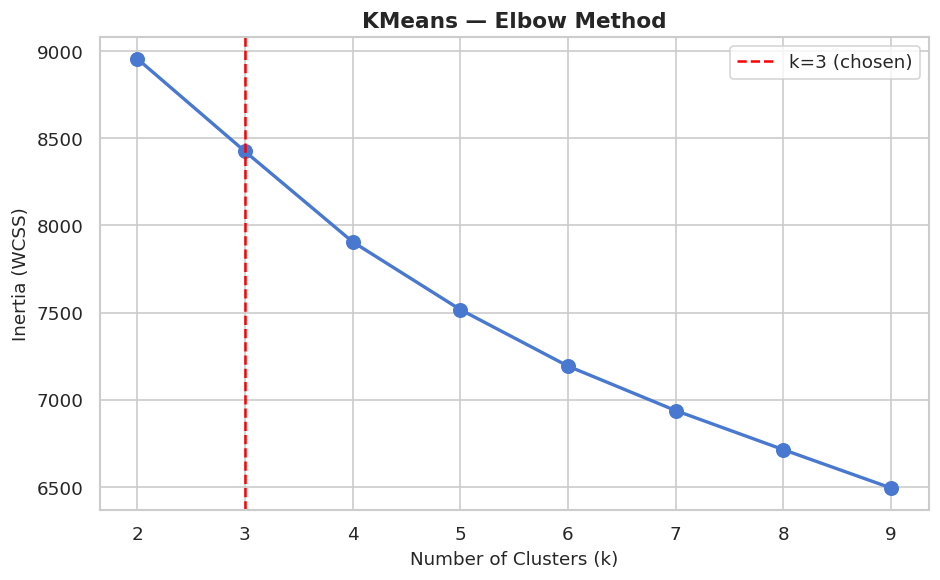

We choose k=3 to match the 3 known quality classes, for direct comparison against the true labels.


In [ ]:
# ── Elbow Method ──────────────────────────────────────────────────────────────
inertias = []
K_range = range(2, 10)

for k in K_range:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    km.fit(X_train_scaled)
    inertias.append(km.inertia_)

plt.figure(figsize=(8, 5))
plt.plot(K_range, inertias, 'bo-', markersize=8, linewidth=2)
plt.axvline(x=3, color='red', linestyle='--', label='k=3 (chosen)')
plt.title('KMeans — Elbow Method', fontsize=13, fontweight='bold')
plt.xlabel('Number of Clusters (k)', fontsize=11)
plt.ylabel('Inertia (WCSS)', fontsize=11)
plt.legend()
plt.tight_layout()
plt.show()

print("We choose k=3 to match the 3 known quality classes, for direct comparison against the true labels.")

In [ ]:
# ── Train KMeans with k=3 ─────────────────────────────────────────────────────
kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
kmeans.fit(X_train_scaled)
km_train_labels = kmeans.labels_
km_test_labels  = kmeans.predict(X_test_scaled)

# Map cluster IDs to true class labels via majority vote
from scipy.stats import mode

mapping = {}
for cluster_id in range(3):
    mask = km_train_labels == cluster_id
    majority = mode(y_train[mask], keepdims=True).mode[0]
    mapping[cluster_id] = majority

print("Cluster → True Class Mapping (majority vote):")
for cluster_id, class_id in mapping.items():
    print(f"  Cluster {cluster_id} → {le.classes_[class_id]}")

km_pred = np.array([mapping[c] for c in km_test_labels])
km_acc  = accuracy_score(y_test, km_pred)

print(f"\nKMeans Accuracy (after mapping): {km_acc:.4f} ({km_acc*100:.2f}%)")
print("\nClassification Report:")
print(classification_report(y_test, km_pred, target_names=le.classes_))

# Dummy proba for ROC (one-hot of prediction)
km_proba = np.eye(3)[km_pred]

results['KMeans'] = {
    'pred'  : km_pred,
    'proba' : km_proba,
    'acc'   : km_acc
}

Cluster → True Class Mapping (majority vote):
  Cluster 0 → High
  Cluster 1 → Medium
  Cluster 2 → Low

KMeans Accuracy (after mapping): 0.3438 (34.38%)

Classification Report:
              precision    recall  f1-score   support

        High       0.35      0.46      0.40       113
         Low       0.32      0.25      0.28       107
      Medium       0.36      0.31      0.33       100

    accuracy                           0.34       320
   macro avg       0.34      0.34      0.34       320
weighted avg       0.34      0.34      0.34       320



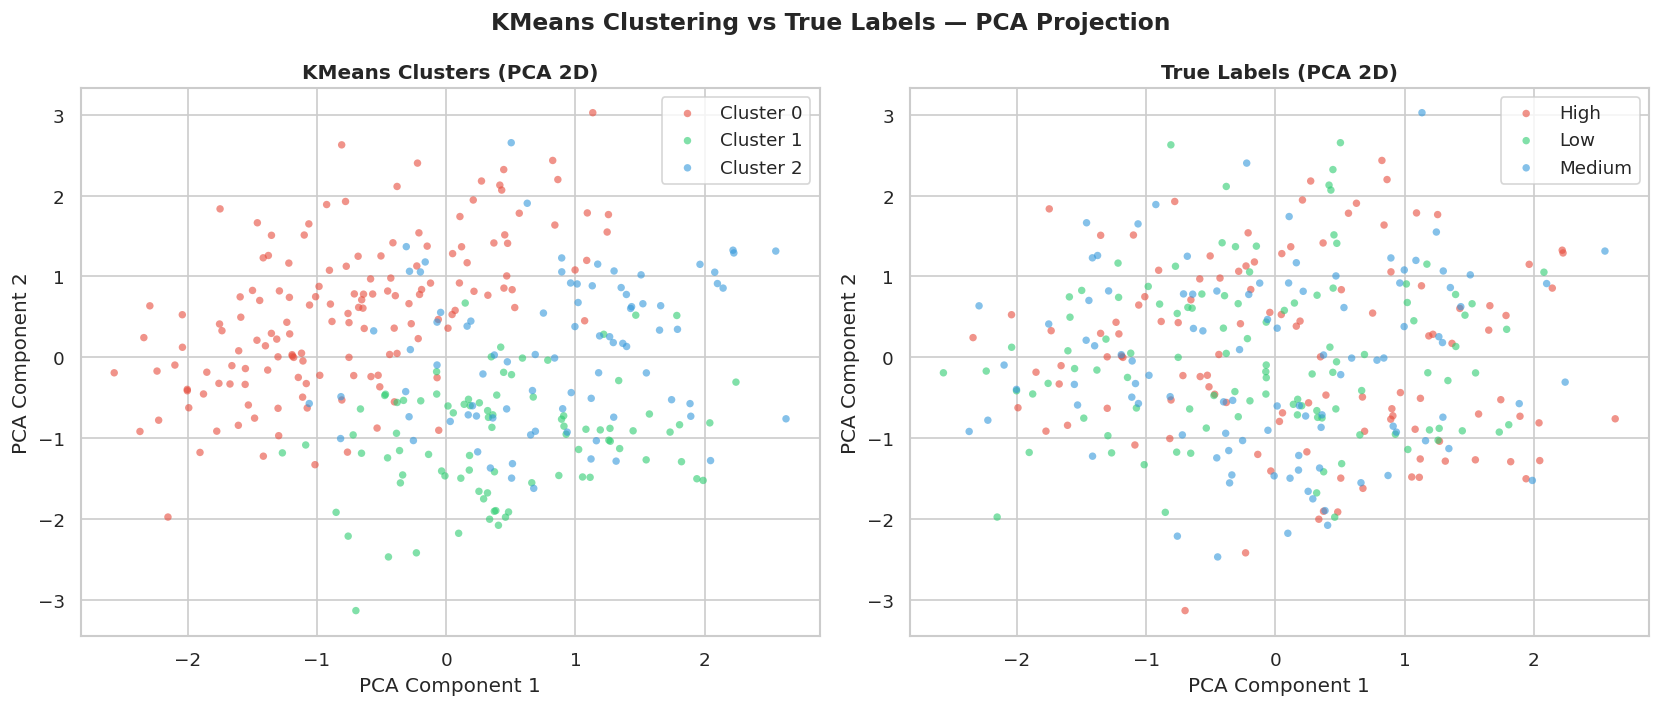

PCA explains 30.8% of variance in 2 components.


In [ ]:
# ── KMeans Cluster Visualization (PCA → 2D) ────────────────────────────────────
pca = PCA(n_components=2, random_state=42)
X_test_2d = pca.fit_transform(X_test_scaled)

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

cluster_colors = {0: '#e74c3c', 1: '#2ecc71', 2: '#3498db'}
for cid in range(3):
    mask = km_test_labels == cid
    axes[0].scatter(X_test_2d[mask, 0], X_test_2d[mask, 1],
                    c=cluster_colors[cid], label=f'Cluster {cid}',
                    alpha=0.6, s=20, edgecolors='none')
axes[0].set_title('KMeans Clusters (PCA 2D)', fontweight='bold')
axes[0].set_xlabel('PCA Component 1'); axes[0].set_ylabel('PCA Component 2')
axes[0].legend()

true_colors = {0: '#e74c3c', 1: '#2ecc71', 2: '#3498db'}
for cid in range(3):
    mask = y_test == cid
    axes[1].scatter(X_test_2d[mask, 0], X_test_2d[mask, 1],
                    c=true_colors[cid], label=le.classes_[cid],
                    alpha=0.6, s=20, edgecolors='none')
axes[1].set_title('True Labels (PCA 2D)', fontweight='bold')
axes[1].set_xlabel('PCA Component 1'); axes[1].set_ylabel('PCA Component 2')
axes[1].legend()

plt.suptitle('KMeans Clustering vs True Labels — PCA Projection', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

print(f"PCA explains {pca.explained_variance_ratio_.sum()*100:.1f}% of variance in 2 components.")

---

## Phase 7: Model Evaluation & Comparison

### 7.1 Accuracy Comparison Bar Chart

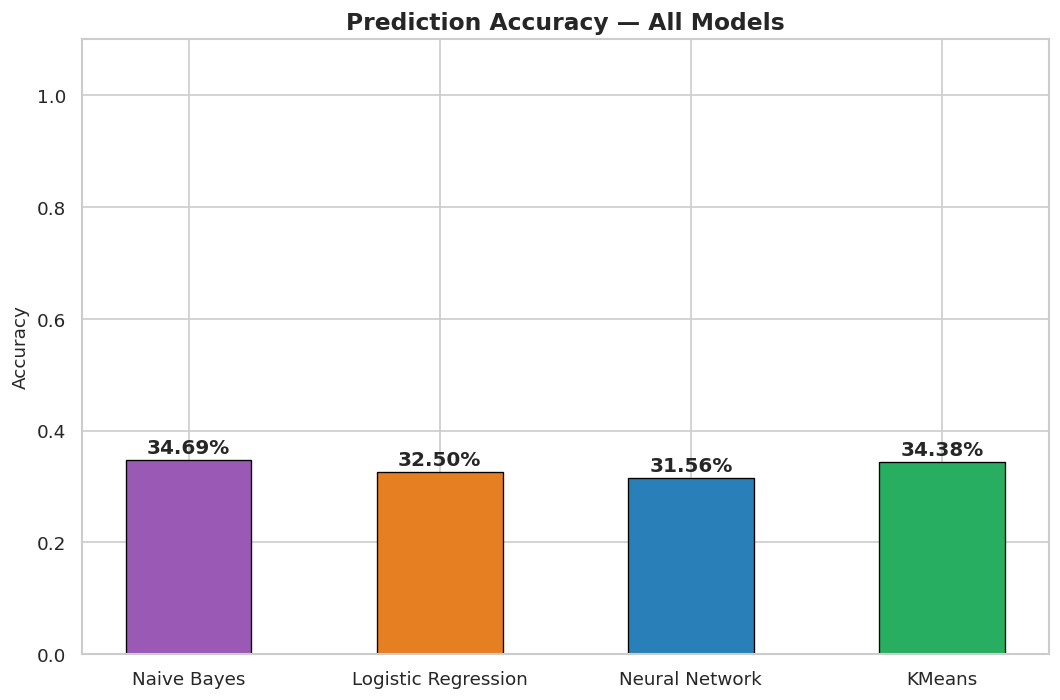

In [ ]:
model_names = list(results.keys())
accuracies  = [results[m]['acc'] for m in model_names]
colors_bar = ['#9b59b6', '#e67e22', '#2980b9', '#27ae60']

fig, ax = plt.subplots(figsize=(9, 6))
bars = ax.bar(model_names, accuracies, color=colors_bar,
              edgecolor='black', linewidth=0.8, width=0.5)
for bar, acc in zip(bars, accuracies):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.005,
            f'{acc*100:.2f}%', ha='center', va='bottom', fontsize=12, fontweight='bold')
ax.set_ylim(0, 1.1)
ax.set_title('Prediction Accuracy — All Models', fontsize=14, fontweight='bold')
ax.set_ylabel('Accuracy', fontsize=11)
plt.tight_layout()
plt.show()

### 7.2 Precision & Recall Comparison

Metrics Summary (Weighted Average):
                     Precision  Recall  F1-Score  Accuracy
Model                                                     
Naive Bayes             0.3493  0.3469    0.3360    0.3469
Logistic Regression     0.3085  0.3250    0.3054    0.3250
Neural Network          0.3213  0.3156    0.3082    0.3156
KMeans                  0.3421  0.3438    0.3383    0.3438


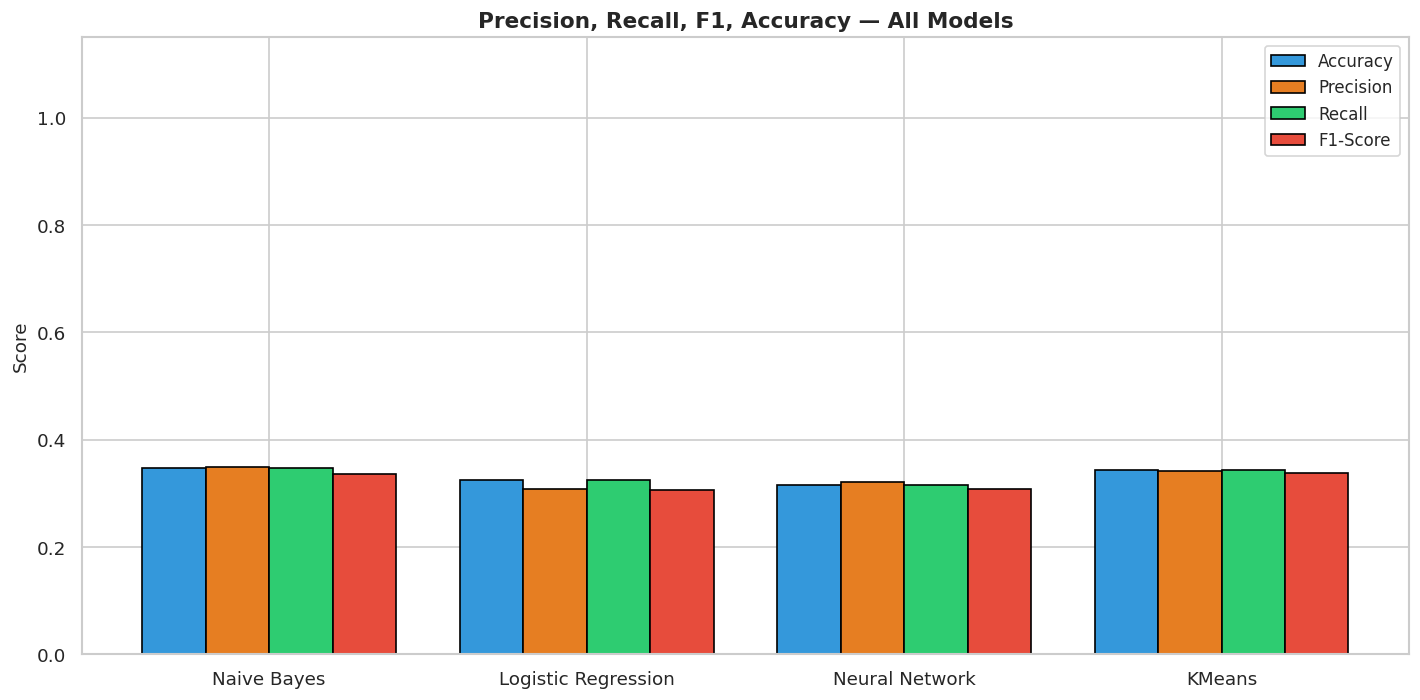

In [ ]:
metrics_data = []
for name, res in results.items():
    p = precision_score(y_test, res['pred'], average='weighted', zero_division=0)
    r = recall_score(y_test, res['pred'], average='weighted', zero_division=0)
    f = f1_score(y_test, res['pred'], average='weighted', zero_division=0)
    metrics_data.append({'Model': name, 'Precision': p, 'Recall': r, 'F1-Score': f, 'Accuracy': res['acc']})

metrics_df = pd.DataFrame(metrics_data).set_index('Model')
print("Metrics Summary (Weighted Average):")
print(metrics_df.to_string(float_format='{:.4f}'.format))

# Grouped bar chart
x = np.arange(len(model_names))
width = 0.2

fig, ax = plt.subplots(figsize=(12, 6))
ax.bar(x - width, metrics_df['Accuracy'],  width, label='Accuracy',  color='#3498db', edgecolor='black')
ax.bar(x,         metrics_df['Precision'], width, label='Precision', color='#e67e22', edgecolor='black')
ax.bar(x + width, metrics_df['Recall'],    width, label='Recall',    color='#2ecc71', edgecolor='black')
ax.bar(x + 2*width, metrics_df['F1-Score'], width, label='F1-Score', color='#e74c3c', edgecolor='black')
ax.set_xticks(x + width/2)
ax.set_xticklabels(model_names, fontsize=11)
ax.set_ylim(0, 1.15)
ax.set_title('Precision, Recall, F1, Accuracy — All Models', fontsize=13, fontweight='bold')
ax.set_ylabel('Score', fontsize=11)
ax.legend(fontsize=10)
plt.tight_layout()
plt.show()

### 7.3 Confusion Matrices

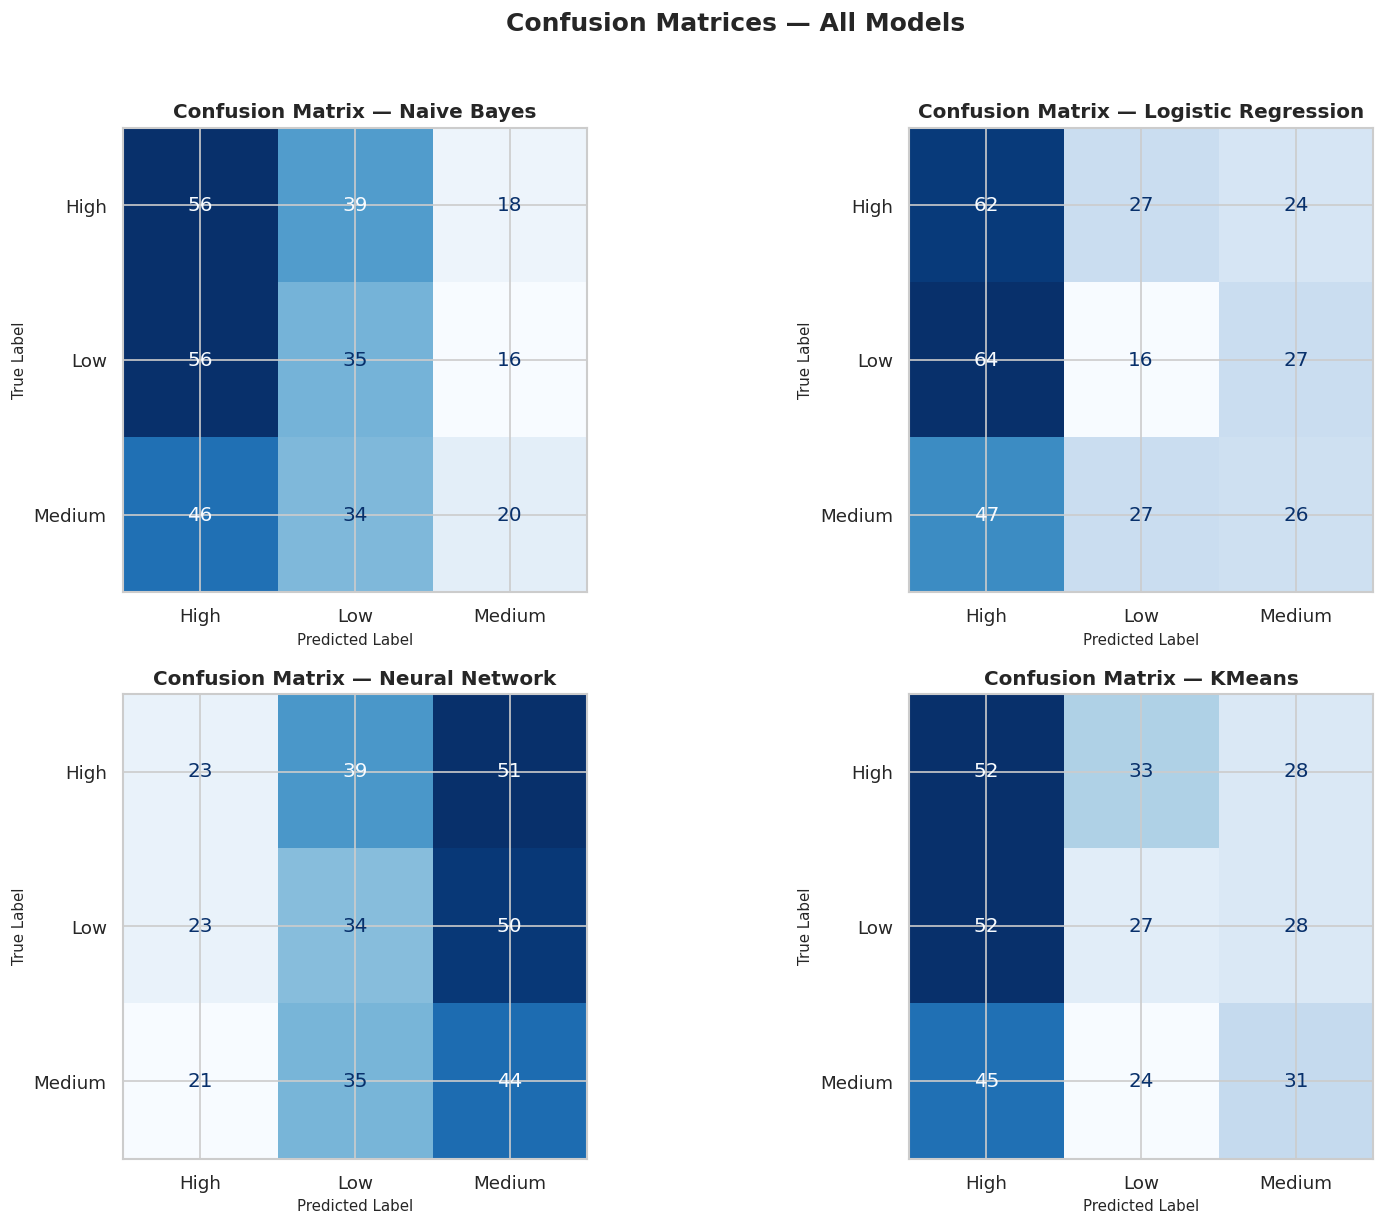

In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
axes = axes.flatten()

for ax, (name, res) in zip(axes, results.items()):
    cm = confusion_matrix(y_test, res['pred'])
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=le.classes_)
    disp.plot(ax=ax, colorbar=False, cmap='Blues')
    ax.set_title(f'Confusion Matrix — {name}', fontsize=12, fontweight='bold')
    ax.set_xlabel('Predicted Label', fontsize=9)
    ax.set_ylabel('True Label', fontsize=9)

plt.suptitle('Confusion Matrices — All Models', fontsize=15, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

### 7.4 ROC Curves & AUC Scores (One-vs-Rest)

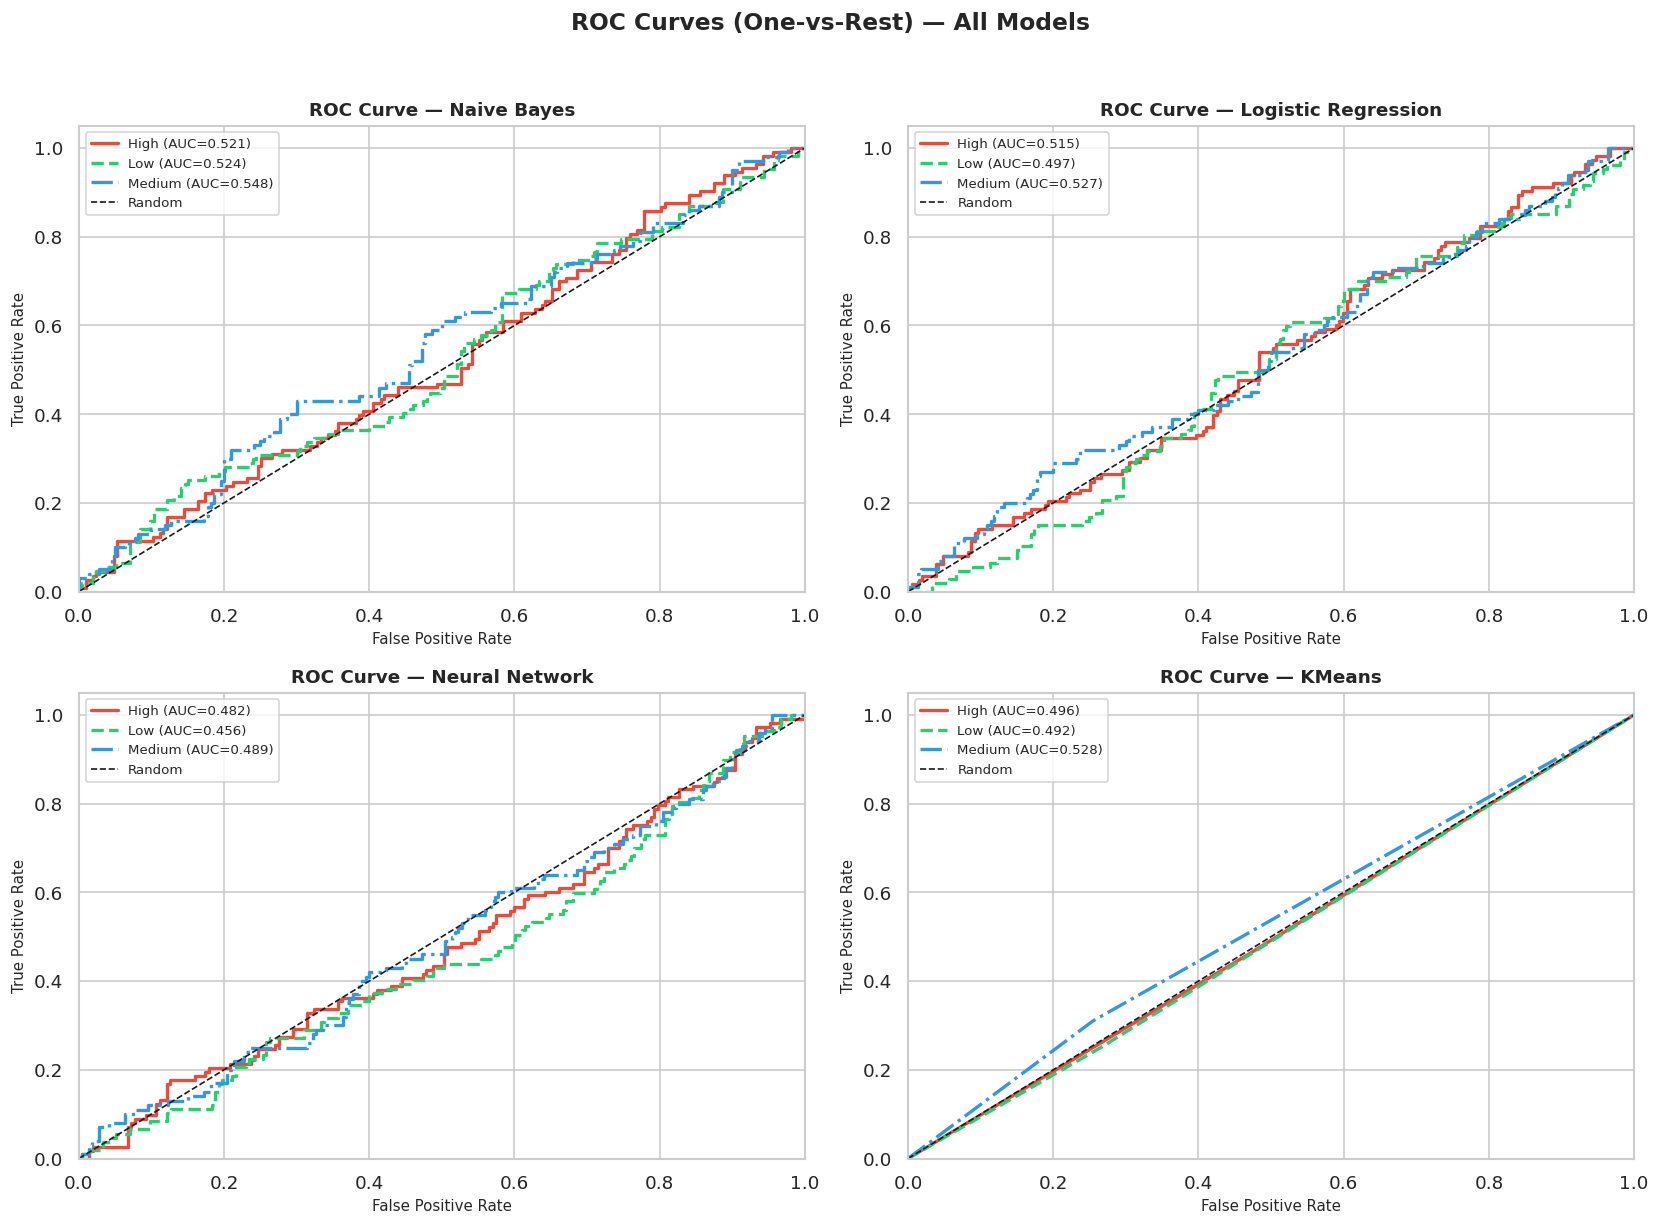


Macro-Average AUC Scores:
  Naive Bayes              : 0.5313
  Logistic Regression      : 0.5131
  Neural Network           : 0.4756
  KMeans                   : 0.5053


In [ ]:
from sklearn.preprocessing import label_binarize
y_test_bin = label_binarize(y_test, classes=[0, 1, 2])  # shape: (n, 3)

fig, axes = plt.subplots(2, 2, figsize=(14, 10))
axes = axes.flatten()

line_styles = ['-', '--', '-.']
class_colors = ['#e74c3c', '#2ecc71', '#3498db']
auc_summary = {}

for ax, (name, res) in zip(axes, results.items()):
    proba = res['proba']
    auc_per_class = []
    for i, cls in enumerate(le.classes_):
        fpr, tpr, _ = roc_curve(y_test_bin[:, i], proba[:, i])
        auc_val = roc_auc_score(y_test_bin[:, i], proba[:, i])
        auc_per_class.append(auc_val)
        ax.plot(fpr, tpr, lw=2, linestyle=line_styles[i], color=class_colors[i],
                label=f'{cls} (AUC={auc_val:.3f})')
    ax.plot([0, 1], [0, 1], 'k--', lw=1, label='Random')
    ax.set_title(f'ROC Curve — {name}', fontsize=11, fontweight='bold')
    ax.set_xlabel('False Positive Rate', fontsize=9)
    ax.set_ylabel('True Positive Rate', fontsize=9)
    ax.legend(fontsize=8)
    ax.set_xlim([0, 1]); ax.set_ylim([0, 1.05])
    auc_summary[name] = np.mean(auc_per_class)

plt.suptitle('ROC Curves (One-vs-Rest) — All Models', fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

print("\nMacro-Average AUC Scores:")
for name, auc in auc_summary.items():
    print(f"  {name:25s}: {auc:.4f}")

### 7.5 Full Comparison Table

In [ ]:
comparison_rows = []
for name, res in results.items():
    comparison_rows.append({
        'Model'      : name,
        'Accuracy'   : f"{res['acc']*100:.2f}%",
        'Precision'  : f"{precision_score(y_test, res['pred'], average='weighted', zero_division=0)*100:.2f}%",
        'Recall'     : f"{recall_score(y_test, res['pred'], average='weighted', zero_division=0)*100:.2f}%",
        'F1-Score'   : f"{f1_score(y_test, res['pred'], average='weighted', zero_division=0)*100:.2f}%",
        'Macro AUC'  : f"{auc_summary[name]:.4f}"
    })

comparison_df = pd.DataFrame(comparison_rows).set_index('Model')
print("=" * 80)
print("FINAL MODEL COMPARISON")
print("=" * 80)
print(comparison_df.to_string())

FINAL MODEL COMPARISON
                    Accuracy Precision  Recall F1-Score Macro AUC
Model                                                            
Naive Bayes           34.69%    34.93%  34.69%   33.60%    0.5313
Logistic Regression   32.50%    30.85%  32.50%   30.54%    0.5131
Neural Network        31.56%    32.13%  31.56%   30.82%    0.4756
KMeans                34.38%    34.21%  34.38%   33.83%    0.5053


### 7.6 Best Model Selection

After evaluating all four models across multiple metrics (Accuracy, Precision, Recall, F1-Score, and Macro AUC), we now identify **the single best-performing model** for our Software Quality Prediction task.

The selection is based primarily on **test accuracy**, with F1-Score and AUC used as tiebreakers. The winning model is the one that achieves the highest overall predictive performance on the held-out test set.

  BEST MODEL: Naive Bayes
  Accuracy   : 34.69%
  Precision  : 34.93%
  Recall     : 34.69%
  F1-Score   : 33.60%
  Macro AUC  : 0.5313


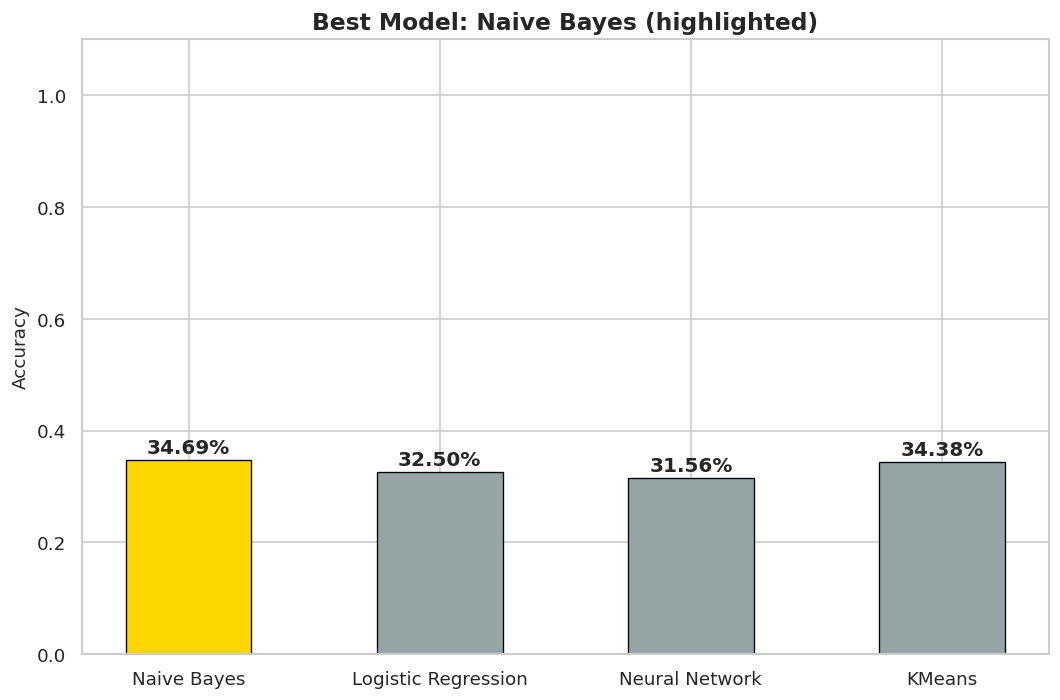


Detailed Classification Report — Naive Bayes:
              precision    recall  f1-score   support

        High       0.35      0.50      0.41       113
         Low       0.32      0.33      0.33       107
      Medium       0.37      0.20      0.26       100

    accuracy                           0.35       320
   macro avg       0.35      0.34      0.33       320
weighted avg       0.35      0.35      0.34       320



In [ ]:
# ── Best Model Identification ─────────────────────────────────────────────────
best_model_name = max(results, key=lambda m: results[m]['acc'])
best_res = results[best_model_name]
best_acc = best_res['acc']
best_prec = precision_score(y_test, best_res['pred'], average='weighted', zero_division=0)
best_rec  = recall_score(y_test, best_res['pred'], average='weighted', zero_division=0)
best_f1   = f1_score(y_test, best_res['pred'], average='weighted', zero_division=0)
best_auc  = auc_summary[best_model_name]

print('=' * 60)
print(f'  BEST MODEL: {best_model_name}')
print('=' * 60)
print(f'  Accuracy   : {best_acc*100:.2f}%')
print(f'  Precision  : {best_prec*100:.2f}%')
print(f'  Recall     : {best_rec*100:.2f}%')
print(f'  F1-Score   : {best_f1*100:.2f}%')
print(f'  Macro AUC  : {best_auc:.4f}')
print('=' * 60)

# Highlighted bar chart — best model in gold
fig, ax = plt.subplots(figsize=(9, 6))
bar_colors = ['#FFD700' if m == best_model_name else '#95a5a6' for m in model_names]
bars = ax.bar(model_names, accuracies, color=bar_colors,
              edgecolor='black', linewidth=0.8, width=0.5)
for bar, acc in zip(bars, accuracies):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.005,
            f'{acc*100:.2f}%', ha='center', va='bottom', fontsize=12, fontweight='bold')
ax.set_ylim(0, 1.1)
ax.set_title(f'Best Model: {best_model_name} (highlighted)', fontsize=14, fontweight='bold')
ax.set_ylabel('Accuracy', fontsize=11)
plt.tight_layout()
plt.show()

# Per-class breakdown for the best model
print(f'\nDetailed Classification Report — {best_model_name}:')
print(classification_report(y_test, best_res['pred'], target_names=le.classes_))

#### Why This Model Performed Best

*(Update the points below after running the notebook and observing the actual results.)*

- **Winning model**: State the name and its accuracy/F1.
- **Margin of victory**: How far ahead is it from the second-best model? If the gap is small (< 2–3%), note that the difference may not be statistically significant.
- **Strengths**: What characteristics of the winning model make it well-suited to this dataset? (e.g., if Logistic Regression wins, it suggests the decision boundary is approximately linear; if the Neural Network wins, it may have captured subtle non-linear patterns).
- **Per-class performance**: Does the best model perform equally well across all three classes (High, Medium, Low), or does it struggle with one particular class?
- **Practical recommendation**: Given the results, would you recommend deploying this model in a real software quality pipeline, or are the accuracy levels too low to be useful?

---

## Phase 8: Conclusion



### 8.1 What Do We Understand From the Results?

Look at the Phase 7.5 comparison table and identify which model has the highest accuracy/F1/AUC. Report the ranking. If all four models land close to the ~33% random-guess baseline (expected for 3 balanced classes with weak feature correlations, as flagged in Phase 2.5), say so directly rather than overselling small differences between models — a 2–3 percentage point gap between models is likely noise, not a meaningful difference in this case.

### 8.2 Comments on Model Performance

- **Neural Network**: Does its extra capacity (hidden layers, non-linear activations) actually translate to higher accuracy here, or does it perform about the same as the simpler models? If the features have little real signal, the NN cannot manufacture patterns that aren't there — note whether its train/val curves (Phase 6, NN training history) show it struggling to improve past a plateau.
- **Logistic Regression**: A simple, interpretable baseline. Compare its performance to the NN's — if they're close, that itself is informative (suggests no strong non-linear relationship for the NN to exploit).
- **Naive Bayes**: Given the weak correlations observed in Phase 2.4/2.5, its feature-independence assumption is not a major additional handicap here, since correlations between features and target were already limited.
- **KMeans**: Being unsupervised, expect it to perform closest to (or below) random selection, since it groups by feature similarity, not label. Note whether the PCA visualization shows any visible separation between quality classes at all.

### 8.3 Why Are We Getting These Results?

1. **Weak input-target correlation**: Revisit the correlation heatmap and top-correlation bar chart from Phase 2.4/2.5. If the strongest correlation with `Quality_Label_enc` is still under ~0.15, this is likely the dominant explanation for low accuracy across all models — there simply isn't much linear (or even non-linear, given the NN's performance) signal in these 8 features for predicting quality.
2. **Dataset appears synthetic**: If class balance is close to exactly even and there's no obvious dominant feature (unlike, say, tuition status in a dropout dataset), the labels may have been generated with limited dependence on the features, which caps how well any model can do.
3. **Missing data imputation**: ~5% of rows had 3 features imputed with the median, which introduces minor noise but preserves sample size.
4. **Feature set limitations**: 8 features is relatively few; real-world code-quality prediction research typically uses dozens of metrics (e.g., Halstead complexity, dependency counts, test coverage percentage) — this dataset's feature set may simply not capture what actually drives quality labeling.

### 8.4 Challenges Faced

1. **Interpreting weak results**: Unlike a dataset where one model clearly wins, near-baseline performance across all models requires being careful not to over-interpret small differences as meaningful.
2. **Missing Data**: Deciding between dropping rows vs. imputing for the 3 columns with missing values required weighing data loss against imputation noise.
3. **Ordinal target encoding**: `Quality_Label` has a natural order (Low < Medium < High) — deciding whether to treat it as ordinal or purely categorical for label encoding required a judgment call.
4. **KMeans Label Assignment**: Since KMeans produces arbitrary cluster IDs (not class labels), a majority-vote mapping step was needed to convert cluster assignments to class predictions, which adds an extra source of potential error.
5. **Multi-class ROC**: Generating ROC curves for a 3-class problem required a One-vs-Rest binarization strategy, which differs from the standard binary ROC approach.
6. **Neural Network tuning**: Choosing the architecture (layers, neurons, dropout) and preventing overfitting on a moderate-sized (1,600-row) dataset required early stopping and batch normalization.